In [2]:
!python3 ingestion_db.py

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import sqlite3
from scipy.stats import ttest_ind
import scipy.stats as stats
warnings.filterwarnings('ignore')

In [5]:
# creating database connection
conn = sqlite3.connect('inventory.db')

# fetching vendor summary data
df = pd.read_sql_query("select * from vendor_sales_summary", conn)
df.head()

,VendorNumber,VendorName,Brand,Description,PurchasePrice,ActualPrice,Volume,TotalPurchaseQuantity,TotalPurchaseDollars,TotalSalesQuantity,TotalSalesDollars
0,2,"IRA GOLDMAN AND WILLIAMS, LLP",90085,Ch Lilian 09 Ladouys St Este,23.86,36.99,750,8,190.88,18,665.82
1,2,"IRA GOLDMAN AND WILLIAMS, LLP",90609,Flavor Essence Variety 5 Pak,17.00,24.99,162.5,320,5440.00,83,2074.17
2,54,AAPER ALCOHOL & CHEMICAL CO,990,Ethyl Alcohol 200 Proof,105.07,134.49,3750,1,105.07,0,0.00
3,60,ADAMBA IMPORTS INTL INC,771,Bak's Krupnik Honey Liqueur,11.44,14.99,750,39,446.16,47,704.53
4,60,ADAMBA IMPORTS INTL INC,3401,Vesica Vodka,11.10,14.99,1750,6,66.60,0,0.00


In [7]:
#summary statistics
df.describe().T

,count,mean,std,min,25%,50%,75%,max
VendorNumber,10692.0,10650.649458,18753.519148,2.00,3951.0000,7153.000,9552.0000,201359.00
Brand,10692.0,18039.228769,12662.187074,58.00,5793.5000,18761.500,25514.2500,90631.00
PurchasePrice,10692.0,24.385303,109.269375,0.36,6.8400,10.455,19.4825,5681.81
ActualPrice,10692.0,35.643671,148.246016,0.49,10.9900,15.990,28.9900,7499.99
TotalPurchaseQuantity,10692.0,3140.886831,11095.086769,1.00,36.0000,262.000,1975.7500,337660.00
TotalPurchaseDollars,10692.0,30106.693372,123067.799627,0.71,453.4575,3655.465,20738.2450,3811251.60
TotalSalesQuantity,10692.0,3091.414235,10969.514991,0.00,33.0000,262.000,1936.0000,334939.00
TotalSalesDollars,10692.0,42429.604623,167913.295736,0.00,731.7575,5298.840,28749.6850,5101919.51


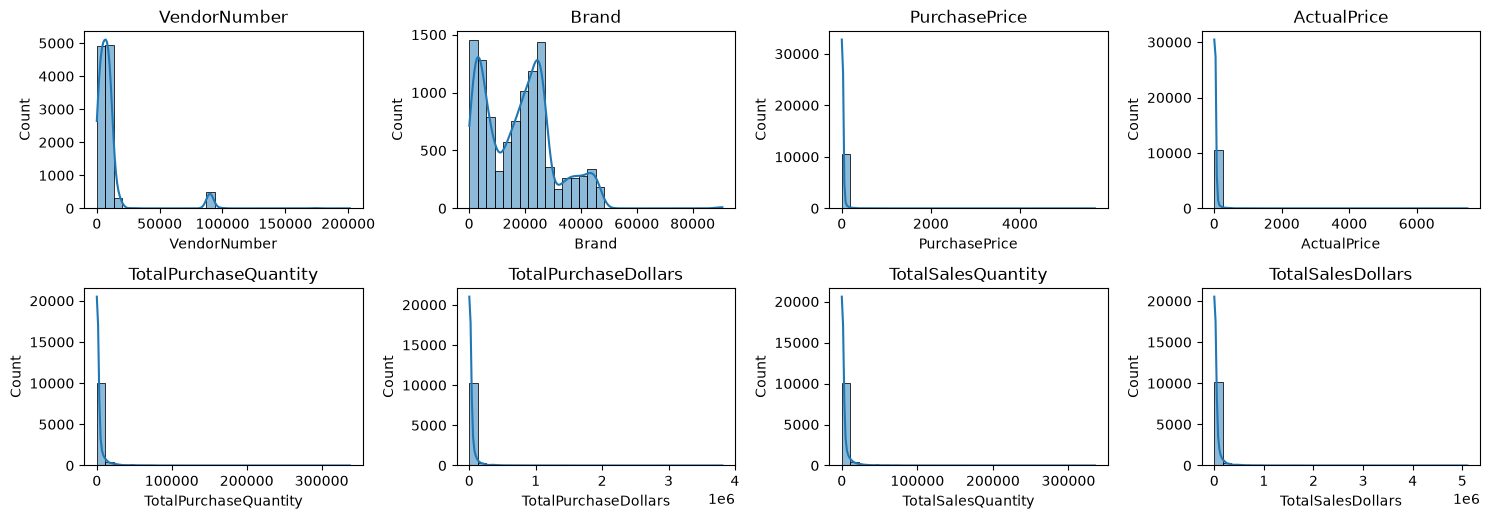

In [8]:
# Distribution Plots for Numerical Columns
numerical_cols = df.select_dtypes(include=np.number).columns

plt.figure(figsize=(15, 10))
for i, col in enumerate(numerical_cols):
    plt.subplot(4, 4, i+1) # Adjust grid layout as needed
    sns.histplot(df[col], kde=True, bins=30)
    plt.title(col)
plt.tight_layout()
plt.show()

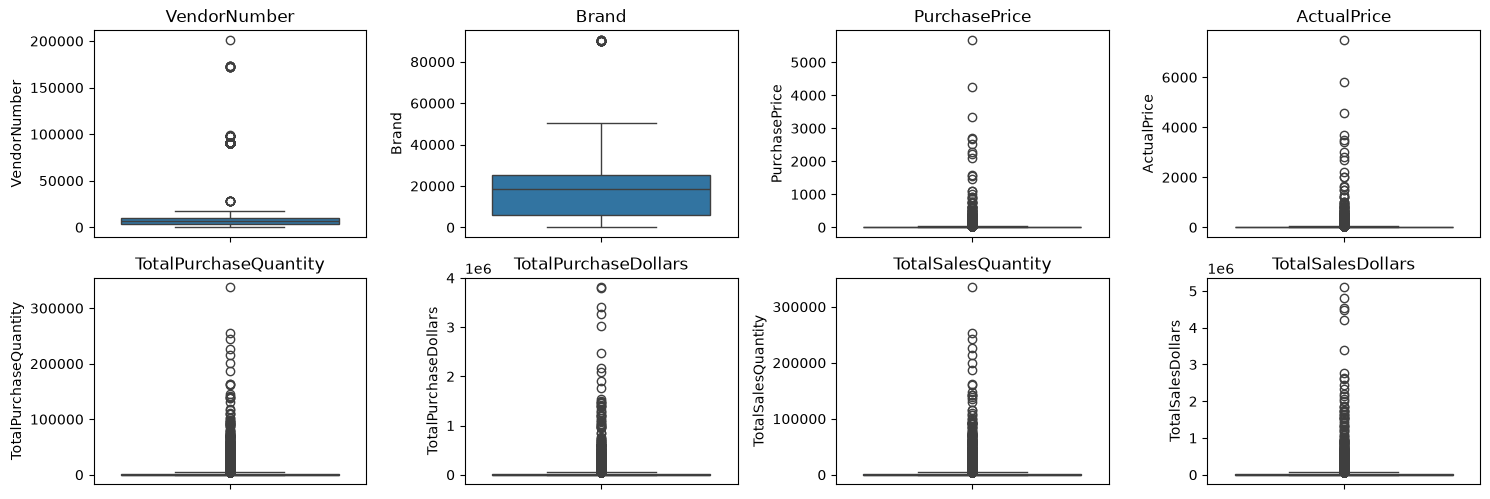

In [9]:
# Outlier Detection with Boxplots
plt.figure(figsize=(15, 10))
for i, col in enumerate(numerical_cols):
    plt.subplot(4, 4, i+1)
    sns.boxplot(y=df[col])
    plt.title(col)
plt.tight_layout()
plt.show()

In [10]:
# let's filter the data by removing inconsistencies
df = pd.read_sql_query("""SELECT * 
FROM vendor_sales_summary 
WHERE GrossProfit > 0 
AND ProfitMargin > 0 
AND TotalSalesQuantity > 0""", conn)

DatabaseError: Execution failed on sql 'SELECT * 
FROM vendor_sales_summary 
WHERE GrossProfit > 0 
AND ProfitMargin > 0 
AND TotalSalesQuantity > 0': no such column: GrossProfit

In [11]:
# Load the raw data from the database
df = pd.read_sql_query("SELECT * FROM vendor_sales_summary", conn)
print(f"Initial rows loaded: {len(df)}")

Initial rows loaded: 10692


In [12]:
# Gross Profit = Total Sales Dollars - Total Purchase Dollars
df['GrossProfit'] = df['TotalSalesDollars'] - df['TotalPurchaseDollars']

In [13]:
# Profit Margin = Gross Profit / Total Sales Dollars
df['ProfitMargin'] = df['GrossProfit'] / df['TotalSalesDollars']

In [14]:
# Apply the filters
df = df[
    (df['GrossProfit'] > 0) & 
    (df['ProfitMargin'] > 0) & 
    (df['TotalSalesQuantity'] > 0)
]

print(f"Cleaned dataset shape: {df.shape}")
df.head()

Cleaned dataset shape: (8572, 13)


,VendorNumber,VendorName,Brand,Description,PurchasePrice,ActualPrice,Volume,TotalPurchaseQuantity,TotalPurchaseDollars,TotalSalesQuantity,TotalSalesDollars,GrossProfit,ProfitMargin
0,2,"IRA GOLDMAN AND WILLIAMS, LLP",90085,Ch Lilian 09 Ladouys St Este,23.86,36.99,750,8,190.88,18,665.82,474.94,0.713316
3,60,ADAMBA IMPORTS INTL INC,771,Bak's Krupnik Honey Liqueur,11.44,14.99,750,39,446.16,47,704.53,258.37,0.366727
6,105,ALTAMAR BRANDS LLC,2529,Right Gin,23.25,29.99,750,12,279.00,12,359.88,80.88,0.224742
7,105,ALTAMAR BRANDS LLC,8412,Tequila Ocho Plata Fresno,35.71,49.99,750,320,11427.20,307,15346.93,3919.73,0.255408
9,200,AMERICAN SPIRITS EXCHANGE,20789,Zin-phomaniac Znfdl,9.73,14.99,750,96,934.08,84,1511.16,577.08,0.381879


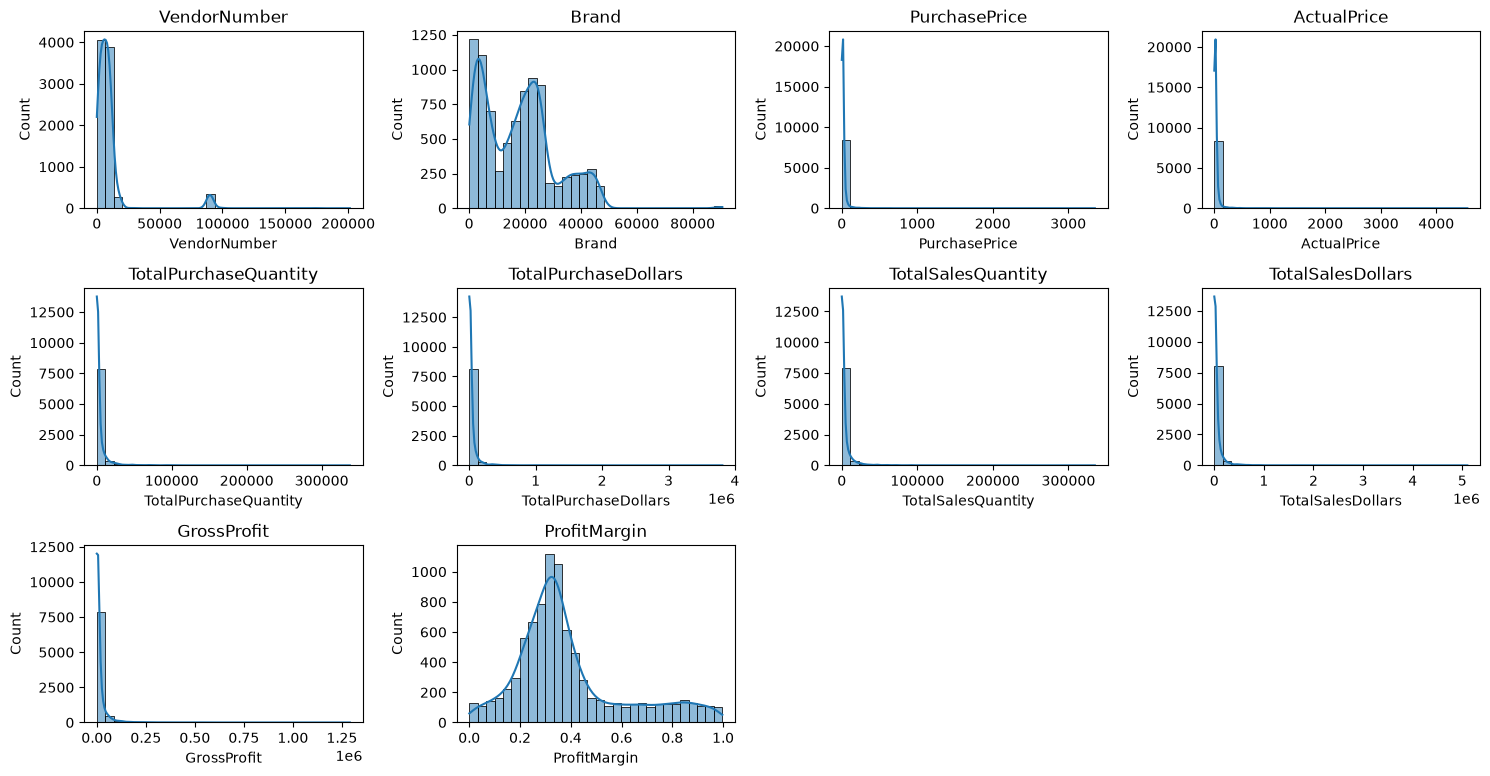

In [15]:
# Distribution Plots for Numerical Columns
numerical_cols = df.select_dtypes(include=np.number).columns

plt.figure(figsize=(15, 10))
for i, col in enumerate(numerical_cols):
    plt.subplot(4, 4, i+1) # Adjust grid layout as needed
    sns.histplot(df[col], kde=True, bins=30)
    plt.title(col)
plt.tight_layout()
plt.show()

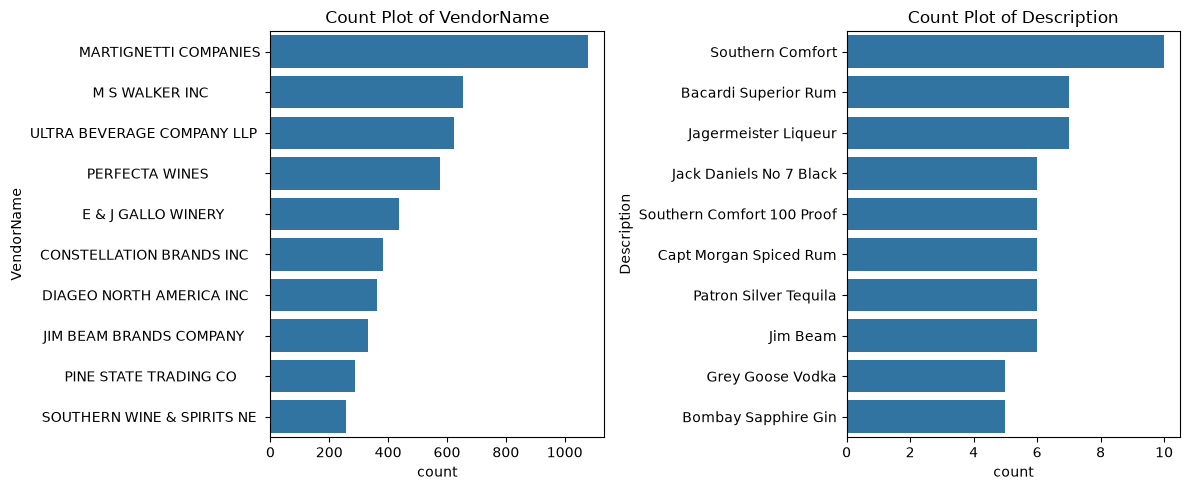

In [16]:
# Count Plots for Categorical Columns
categorical_cols = ["VendorName", "Description"]

plt.figure(figsize=(12, 5))
for i, col in enumerate(categorical_cols):
    plt.subplot(1, 2, i+1)
    sns.countplot(y=df[col], order=df[col].value_counts().index[:10]) # Top 10 categories
    plt.title(f"Count Plot of {col}")
plt.tight_layout()
plt.show()

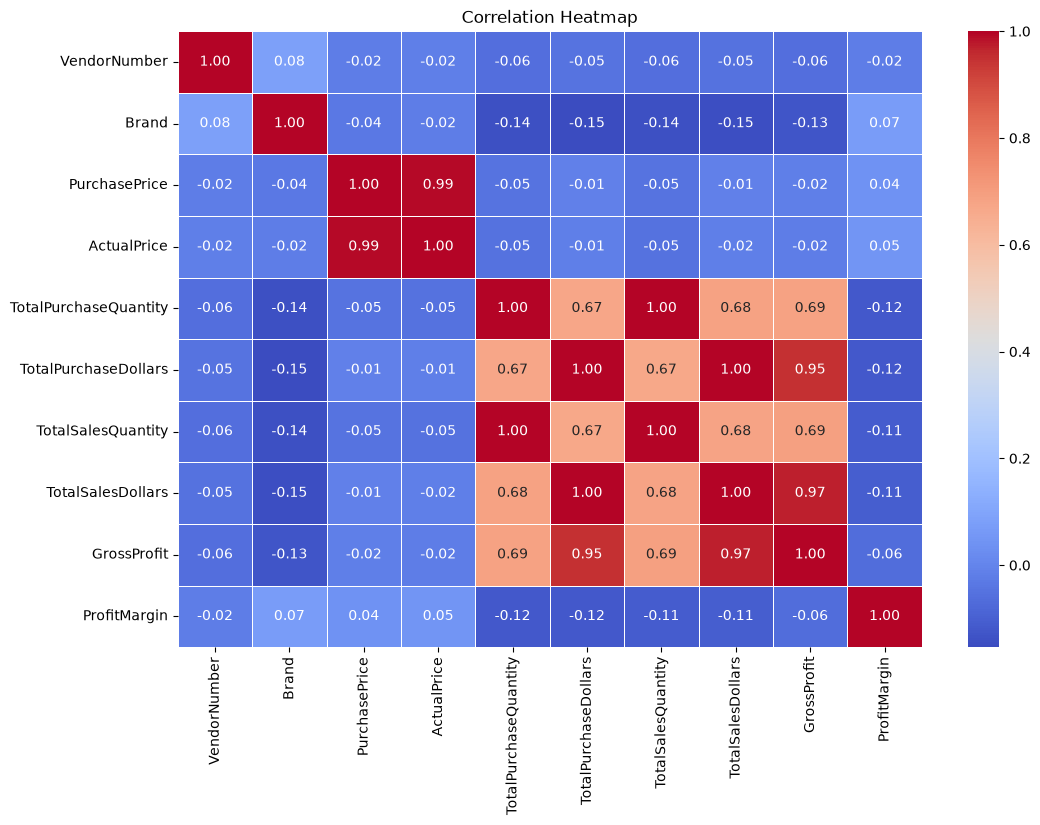

In [17]:
# Correlation Heatmap
plt.figure(figsize=(12, 8))
correlation_matrix = df[numerical_cols].corr()
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.5)
plt.title("Correlation Heatmap")
plt.show()

In [20]:
brand_performance = df.groupby('Description').agg({
    'TotalSalesDollars': 'sum',
    'ProfitMargin': 'mean'
}).reset_index()

In [21]:
low_sales_threshold = brand_performance['TotalSalesDollars'].quantile(0.15)
high_margin_threshold = brand_performance['ProfitMargin'].quantile(0.85)

In [22]:
low_sales_threshold

np.float64(560.7049999999999)

In [24]:
high_margin_threshold

np.float64(0.6527430867085849)

In [25]:
# Filter brands with low sales but high profit margins
target_brands = brand_performance[
    (brand_performance['TotalSalesDollars'] <= low_sales_threshold) & 
    (brand_performance['ProfitMargin'] >= high_margin_threshold)
]

print("Brands with Low Sales but High Profit Margins:")
display(target_brands.sort_values('TotalSalesDollars'))

Brands with Low Sales but High Profit Margins:


,Description,TotalSalesDollars,ProfitMargin
6200,Santa Rita Organic Svgn Bl,9.99,0.664665
2370,Debauchery Pnt Nr,11.58,0.659758
2071,Concannon Glen Ellen Wh Zin,15.95,0.834483
2189,Crown Royal Apple,27.86,0.898062
6238,Sauza Sprklg Wild Berry Marg,27.96,0.821531
...,...,...,...
5075,Nanbu Bijin Southern Beauty,535.68,0.767473
2272,Dad's Hat Rye Whiskey,538.89,0.818516
57,A Bichot Clos Marechaudes,539.94,0.677409
6246,Sbragia Home Ranch Merlot,549.75,0.664447


In [27]:
brand_performance = brand_performance[brand_performance['TotalSalesDollars'] < 10000] # for better visualization

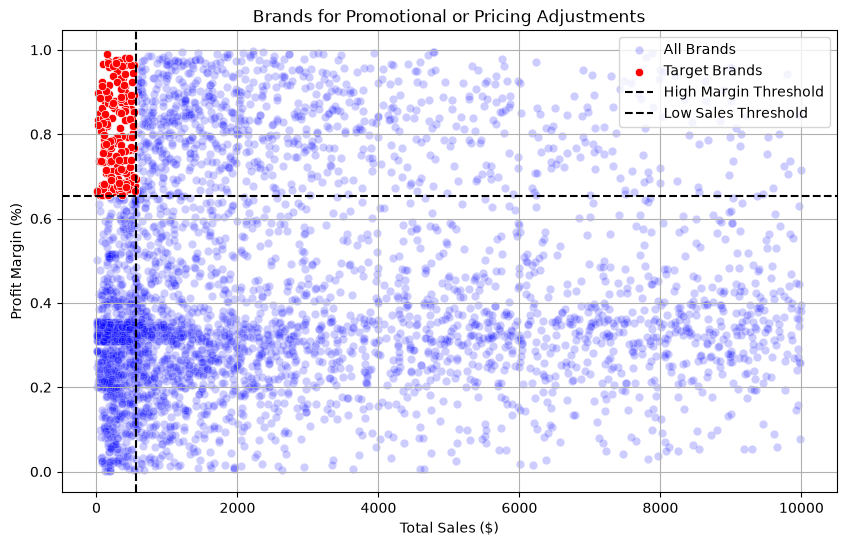

In [28]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=brand_performance, x='TotalSalesDollars', y='ProfitMargin', color='blue', label='All Brands', alpha=0.2)
sns.scatterplot(data=target_brands, x='TotalSalesDollars', y='ProfitMargin', color='red', label='Target Brands')

plt.axhline(high_margin_threshold, linestyle='--', color='black', label='High Margin Threshold')
plt.axvline(low_sales_threshold, linestyle='--', color='black', label='Low Sales Threshold')

plt.xlabel("Total Sales ($)")
plt.ylabel("Profit Margin (%)")
plt.title("Brands for Promotional or Pricing Adjustments")
plt.legend()
plt.grid(True)
plt.show()

In [29]:
# Top Vendors & Brands by Sales Performance
top_vendors = df.groupby("VendorName")["TotalSalesDollars"].sum().nlargest(10)
top_brands = df.groupby("Description")["TotalSalesDollars"].sum().nlargest(10)
top_vendors

VendorName
DIAGEO NORTH AMERICA INC       67990099.42
MARTIGNETTI COMPANIES          39312491.55
PERNOD RICARD USA              32063196.19
JIM BEAM BRANDS COMPANY        31423020.46
BACARDI USA INC                24854817.14
CONSTELLATION BRANDS INC       24218745.65
BROWN-FORMAN CORP              19110523.54
E & J GALLO WINERY             18399899.46
ULTRA BEVERAGE COMPANY LLP     16543016.87
M S WALKER INC                 14730644.63
Name: TotalSalesDollars, dtype: float64

In [30]:
top_brands

Description
Jack Daniels No 7 Black    7964746.76
Tito's Handmade Vodka      7399657.58
Grey Goose Vodka           7209608.06
Capt Morgan Spiced Rum     6356320.62
Absolut 80 Proof           6244752.03
Jameson Irish Whiskey      5715759.69
Ketel One Vodka            5070083.56
Baileys Irish Cream        4150122.07
Kahlua                     3604858.66
Tanqueray                  3456697.90
Name: TotalSalesDollars, dtype: float64

In [32]:
def format_dollars(x):
    if x >= 1e6:
        return f"{x / 1e6:.2f}M"
    elif x >= 1e3:
        return f"{x / 1e3:.2f}K"
    return f"{x:.2f}"

In [33]:
top_brands.apply(lambda x : format_dollars(x))

Description
Jack Daniels No 7 Black    7.96M
Tito's Handmade Vodka      7.40M
Grey Goose Vodka           7.21M
Capt Morgan Spiced Rum     6.36M
Absolut 80 Proof           6.24M
Jameson Irish Whiskey      5.72M
Ketel One Vodka            5.07M
Baileys Irish Cream        4.15M
Kahlua                     3.60M
Tanqueray                  3.46M
Name: TotalSalesDollars, dtype: str

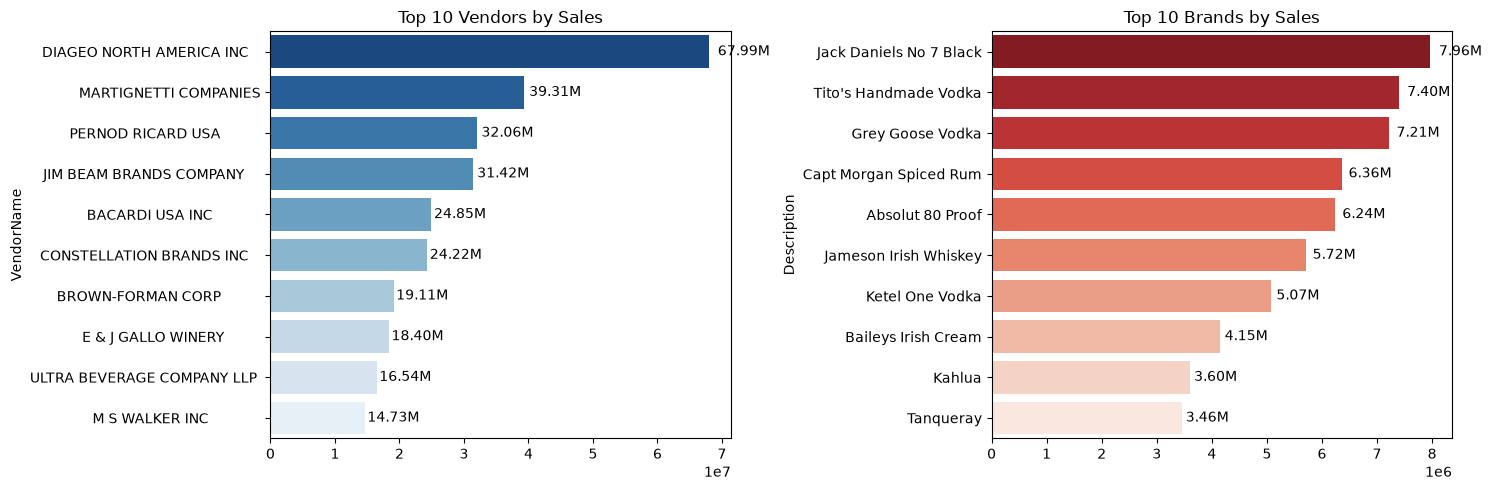

In [34]:
plt.figure(figsize=(15, 5))

# Plot for Top Vendors
plt.subplot(1, 2, 1)
ax1 = sns.barplot(y=top_vendors.index, x=top_vendors.values, palette="Blues_r")
plt.title("Top 10 Vendors by Sales")

for bar in ax1.patches:
    ax1.text(bar.get_width() + (bar.get_width() * 0.02),
             bar.get_y() + bar.get_height() / 2,
             format_dollars(bar.get_width()),
             ha='left', va='center', fontsize=10, color='black')

# Plot for Top Brands
plt.subplot(1, 2, 2)
ax2 = sns.barplot(y=top_brands.index.astype(str), x=top_brands.values, palette="Reds_r")
plt.title("Top 10 Brands by Sales")

for bar in ax2.patches:
    ax2.text(bar.get_width() + (bar.get_width() * 0.02),
             bar.get_y() + bar.get_height() / 2,
             format_dollars(bar.get_width()),
             ha='left', va='center', fontsize=10, color='black')

plt.tight_layout()
plt.show()

In [37]:
vendor_performance = df.groupby('VendorName').agg({
    'TotalPurchaseDollars': 'sum',
    'GrossProfit': 'sum',
    'TotalSalesDollars': 'sum'
}).reset_index()

In [38]:
vendor_performance['PurchaseContribution'] = vendor_performance['TotalPurchaseDollars'] / vendor_performance['TotalPurchaseDollars'].sum()

In [39]:
vendor_performance

,VendorName,TotalPurchaseDollars,GrossProfit,TotalSalesDollars,PurchaseContribution
0,ADAMBA IMPORTS INTL INC,446.16,258.37,704.53,0.000001
1,ALISA CARR BEVERAGES,25698.12,78772.82,104470.94,0.000084
2,ALTAMAR BRANDS LLC,11706.20,4000.61,15706.81,0.000038
3,AMERICAN SPIRITS EXCHANGE,934.08,577.08,1511.16,0.000003
4,AMERICAN VINTAGE BEVERAGE,104435.68,35167.85,139603.53,0.000340
...,...,...,...,...,...
115,WEIN BAUER INC,42694.64,13522.49,56217.13,0.000139
116,WESTERN SPIRITS BEVERAGE CO,298416.86,106837.97,405254.83,0.000971
117,WILLIAM GRANT & SONS INC,5876538.26,1693337.94,7569876.20,0.019116
118,WINE GROUP INC,5203801.17,3100242.11,8304043.28,0.016927


In [42]:
round(vendor_performance.sort_values('PurchaseContribution', ascending = False),2)

,VendorName,TotalPurchaseDollars,GrossProfit,TotalSalesDollars,PurchaseContribution
25,DIAGEO NORTH AMERICA INC,50097226.16,17892873.26,67990099.42,0.16
57,MARTIGNETTI COMPANIES,25464774.04,13847717.51,39312491.55,0.08
69,PERNOD RICARD USA,23851164.17,8212032.02,32063196.19,0.08
46,JIM BEAM BRANDS COMPANY,23494304.32,7928716.14,31423020.46,0.08
6,BACARDI USA INC,17432020.26,7422796.88,24854817.14,0.06
...,...,...,...,...,...
33,FANTASY FINE WINES CORP,128.64,198.95,327.59,0.00
108,UNCORKED,118.74,58.20,176.94,0.00
86,SILVER MOUNTAIN CIDERS,77.18,265.33,342.51,0.00
16,CAPSTONE INTERNATIONAL,54.64,192.23,246.87,0.00


In [43]:
# Display Top 10 Vendors
top_vendors = vendor_performance.head(10)
top_vendors['TotalSalesDollars'] = top_vendors['TotalSalesDollars'].apply(format_dollars)
top_vendors['TotalPurchaseDollars'] = top_vendors['TotalPurchaseDollars'].apply(format_dollars)
top_vendors['GrossProfit'] = top_vendors['GrossProfit'].apply(format_dollars)
top_vendors

,VendorName,TotalPurchaseDollars,GrossProfit,TotalSalesDollars,PurchaseContribution
0,ADAMBA IMPORTS INTL INC,446.16,258.37,704.53,0.000001
1,ALISA CARR BEVERAGES,25.70K,78.77K,104.47K,0.000084
2,ALTAMAR BRANDS LLC,11.71K,4.00K,15.71K,0.000038
3,AMERICAN SPIRITS EXCHANGE,934.08,577.08,1.51K,0.000003
4,AMERICAN VINTAGE BEVERAGE,104.44K,35.17K,139.60K,0.000340
5,ATLANTIC IMPORTING COMPANY,41.12K,18.16K,59.27K,0.000134
6,BACARDI USA INC,17.43M,7.42M,24.85M,0.056704
7,BANFI PRODUCTS CORP,1.61M,1.02M,2.63M,0.005231
8,BLACK PRINCE DISTILLERY INC,5.85K,5.75K,11.60K,0.000019
9,BLACK ROCK SPIRITS LLC,1.15K,897.08,2.05K,0.000004


In [46]:
top_vendors['PurchaseContribution'].sum()

np.float64(0.06255790392835016)

In [48]:
top_vendors['Cumulative_Contribution%'] = top_vendors['PurchaseContribution'].cumsum()
top_vendors

,VendorName,TotalPurchaseDollars,GrossProfit,TotalSalesDollars,PurchaseContribution,Cumulative_Contribution%
0,ADAMBA IMPORTS INTL INC,446.16,258.37,704.53,0.000001,0.000001
1,ALISA CARR BEVERAGES,25.70K,78.77K,104.47K,0.000084,0.000085
2,ALTAMAR BRANDS LLC,11.71K,4.00K,15.71K,0.000038,0.000123
3,AMERICAN SPIRITS EXCHANGE,934.08,577.08,1.51K,0.000003,0.000126
4,AMERICAN VINTAGE BEVERAGE,104.44K,35.17K,139.60K,0.000340,0.000466
5,ATLANTIC IMPORTING COMPANY,41.12K,18.16K,59.27K,0.000134,0.000600
6,BACARDI USA INC,17.43M,7.42M,24.85M,0.056704,0.057304
7,BANFI PRODUCTS CORP,1.61M,1.02M,2.63M,0.005231,0.062535
8,BLACK PRINCE DISTILLERY INC,5.85K,5.75K,11.60K,0.000019,0.062554
9,BLACK ROCK SPIRITS LLC,1.15K,897.08,2.05K,0.000004,0.062558


In [49]:
# 1. Permanently sort the dataframe from highest to lowest contribution
vendor_performance = vendor_performance.sort_values('PurchaseContribution', ascending=False)

# 2. Grab the true top 10 vendors
top_vendors = vendor_performance.head(10).copy()

# 3. Create the professor's column names
top_vendors['Purchase_Contribution%'] = top_vendors['PurchaseContribution']
top_vendors['Cumulative_Contribution%'] = top_vendors['Purchase_Contribution%'].cumsum()

# 4. Format the dollar values into human-readable text strings
top_vendors['TotalSalesDollars'] = top_vendors['TotalSalesDollars'].apply(format_dollars)
top_vendors['TotalPurchaseDollars'] = top_vendors['TotalPurchaseDollars'].apply(format_dollars)
top_vendors['GrossProfit'] = top_vendors['GrossProfit'].apply(format_dollars)

# Display the correct matching table
top_vendors

,VendorName,TotalPurchaseDollars,GrossProfit,TotalSalesDollars,PurchaseContribution,Purchase_Contribution%,Cumulative_Contribution%
25,DIAGEO NORTH AMERICA INC,50.10M,17.89M,67.99M,0.162961,0.162961,0.162961
57,MARTIGNETTI COMPANIES,25.46M,13.85M,39.31M,0.082834,0.082834,0.245795
69,PERNOD RICARD USA,23.85M,8.21M,32.06M,0.077585,0.077585,0.323380
46,JIM BEAM BRANDS COMPANY,23.49M,7.93M,31.42M,0.076424,0.076424,0.399804
6,BACARDI USA INC,17.43M,7.42M,24.85M,0.056704,0.056704,0.456508
20,CONSTELLATION BRANDS INC,15.27M,8.95M,24.22M,0.049684,0.049684,0.506192
11,BROWN-FORMAN CORP,13.24M,5.87M,19.11M,0.043065,0.043065,0.549257
30,E & J GALLO WINERY,12.07M,6.33M,18.40M,0.039258,0.039258,0.588514
107,ULTRA BEVERAGE COMPANY LLP,11.17M,5.38M,16.54M,0.036327,0.036327,0.624841
80,SAZERAC CO INC,9.77M,4.15M,13.91M,0.031768,0.031768,0.656609


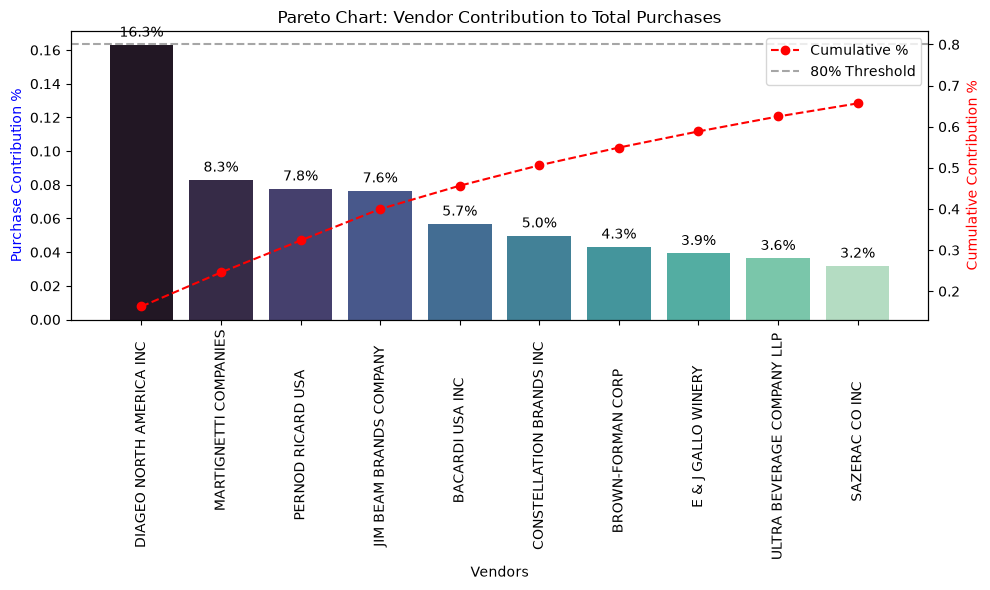

In [50]:
fig, ax1 = plt.subplots(figsize=(10, 6))

# Bar plot for Purchase Contribution%
sns.barplot(x=top_vendors['VendorName'], y=top_vendors['Purchase_Contribution%'], palette="mako", ax=ax1)

# Adding text labels on top of the bars
for i, value in enumerate(top_vendors['Purchase_Contribution%']):
    ax1.text(i, value + 0.005, f"{value*100:.1f}%", ha='center', fontsize=10, color='black')

# Line Plot for Cumulative Contribution%
ax2 = ax1.twinx()
ax2.plot(top_vendors['VendorName'], top_vendors['Cumulative_Contribution%'], color='red', marker='o', linestyle='dashed', label='Cumulative %')

# Formatting labels and axes
ax1.set_xticklabels(top_vendors['VendorName'], rotation=90)
ax1.set_ylabel('Purchase Contribution %', color='blue')
ax2.set_ylabel('Cumulative Contribution %', color='red')
ax1.set_xlabel('Vendors')
ax1.set_title('Pareto Chart: Vendor Contribution to Total Purchases')

# Target baseline (e.g., 80% line for Pareto principle analysis)
ax2.axhline(y=0.80, color='gray', linestyle='dashed', alpha=0.7, label='80% Threshold')
ax2.legend(loc='upper right')

plt.tight_layout()
plt.show()

In [51]:
print(f"Total Purchase Contribution of top 10 vendors is {round(top_vendors['Purchase_Contribution%'].sum(), 2)} %")

Total Purchase Contribution of top 10 vendors is 0.66 %


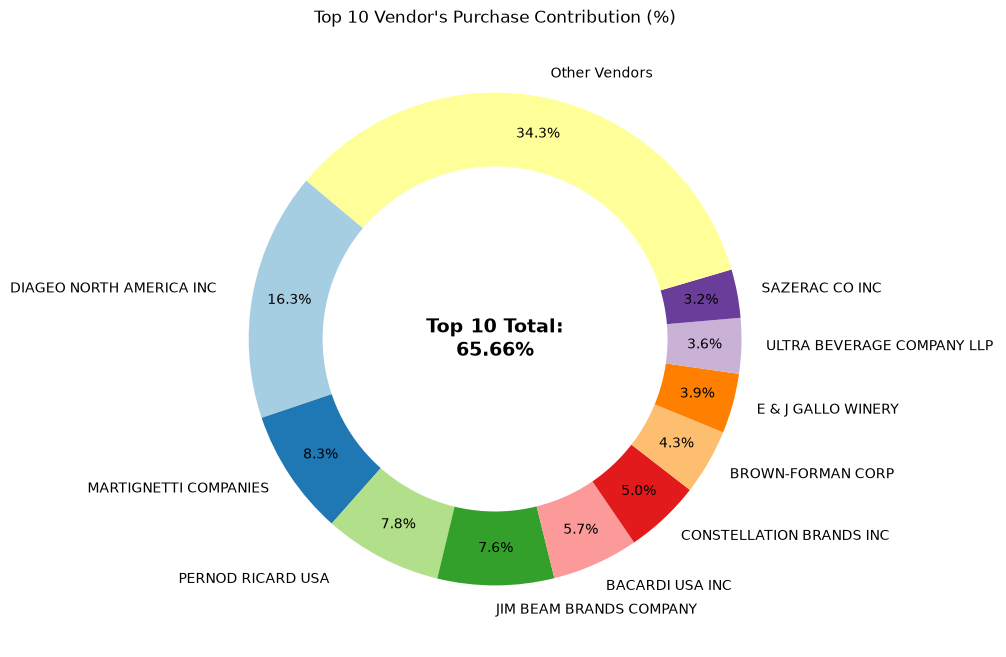

In [53]:
vendors = list(top_vendors['VendorName'].values)

# Multiply by 100 to convert decimals (0.16 -> 16.0) into true percentage values
purchase_contributions = list(top_vendors['Purchase_Contribution%'].values * 100)
total_contribution = sum(purchase_contributions)
remaining_contribution = 100 - total_contribution

# Append "Other Vendors" category
vendors.append("Other Vendors")
purchase_contributions.append(remaining_contribution)

# Donut Chart
fig, ax = plt.subplots(figsize=(8, 8))
wedges, texts, autotexts = ax.pie(purchase_contributions, labels=vendors, autopct='%1.1f%%',
                                  startangle=140, pctdistance=0.85, colors=plt.cm.Paired.colors)

# Draw a white circle in the center to create a "donut" effect
centre_circle = plt.Circle((0, 0), 0.70, fc='white')
fig.gca().add_artist(centre_circle)

# Add Total Contribution annotation in the center
plt.text(0, 0, f"Top 10 Total:\n{total_contribution:.2f}%", fontsize=14, fontweight='bold', ha='center', va='center')

plt.title("Top 10 Vendor's Purchase Contribution (%)")
plt.show()

In [54]:
df['UnitPurchasePrice'] = df['TotalPurchaseDollars'] / df['TotalPurchaseQuantity']

In [55]:
df["OrderSize"] = pd.qcut(df["TotalPurchaseQuantity"], q=3, labels=["Small", "Medium", "Large"])

In [56]:
df[['OrderSize', 'TotalPurchaseQuantity']]

,OrderSize,TotalPurchaseQuantity
0,Small,8
3,Small,39
6,Small,12
7,Medium,320
9,Medium,96
...,...,...
10682,Medium,138
10683,Medium,267
10685,Medium,554
10690,Medium,1232


In [57]:
df.groupby('OrderSize')[['UnitPurchasePrice']].mean()

,UnitPurchasePrice
OrderSize,
Small,39.048936
Medium,15.498932
Large,10.773024


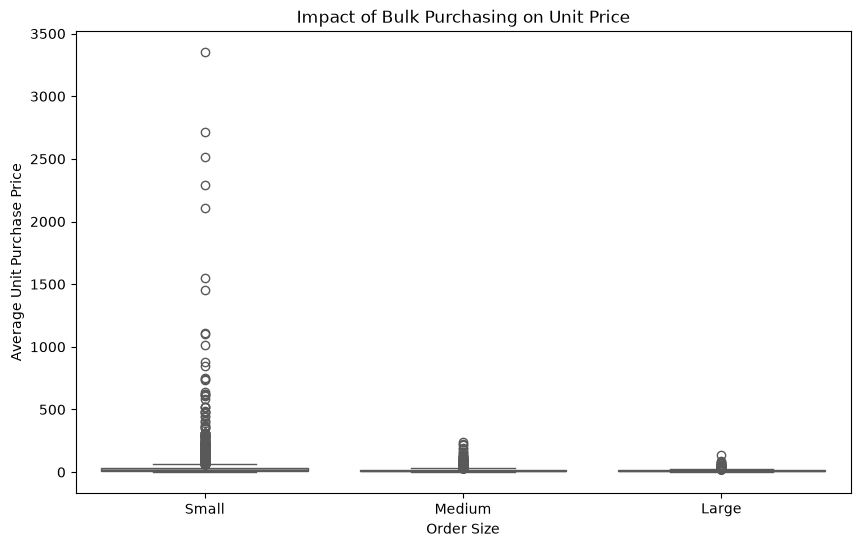

In [58]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x="OrderSize", y="UnitPurchasePrice", palette="Set2")
plt.title("Impact of Bulk Purchasing on Unit Price")
plt.xlabel("Order Size")
plt.ylabel("Average Unit Purchase Price")
plt.show()

In [60]:
# Calculate the missing StockTurnover column
df['StockTurnover'] = df['TotalSalesQuantity'] / df['TotalPurchaseQuantity']

In [61]:
df[df['StockTurnover']<1]

,VendorNumber,VendorName,Brand,Description,PurchasePrice,ActualPrice,Volume,TotalPurchaseQuantity,TotalPurchaseDollars,TotalSalesQuantity,TotalSalesDollars,GrossProfit,ProfitMargin,UnitPurchasePrice,OrderSize,StockTurnover
7,105,ALTAMAR BRANDS LLC,8412,Tequila Ocho Plata Fresno,35.71,49.99,750,320,11427.20,307,15346.93,3919.73,0.255408,35.71,Medium,0.959375
9,200,AMERICAN SPIRITS EXCHANGE,20789,Zin-phomaniac Znfdl,9.73,14.99,750,96,934.08,84,1511.16,577.08,0.381879,9.73,Medium,0.875000
12,388,ATLANTIC IMPORTING COMPANY,2034,Glendalough Double Barrel,21.32,32.99,750,1777,37885.64,1587,45645.13,7759.49,0.169996,21.32,Large,0.893078
15,480,BACARDI USA INC,126,Grey Goose Vodka,20.14,32.99,1000,59878,1205942.92,58013,1736610.87,530667.95,0.305577,20.14,Large,0.968853
19,480,BACARDI USA INC,278,Cazadores Reposado Tequila,21.96,28.99,1000,80,1756.80,69,1997.31,240.51,0.120417,21.96,Small,0.862500
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10666,90058,ZORVINO VINEYARDS,25126,Zorvino Vyds Peachez,6.62,9.99,750,1778,11770.36,1551,15494.49,3724.13,0.240352,6.62,Large,0.872328
10682,172662,SWEETWATER FARM,2191,Clark & Chesterfield Whiskey,14.70,19.99,375,138,2028.60,125,2498.75,470.15,0.188154,14.70,Medium,0.905797
10683,172662,SWEETWATER FARM,2265,Monadnock Moonshine,21.47,28.99,750,267,5732.49,222,6435.78,703.29,0.109278,21.47,Medium,0.831461
10685,172662,SWEETWATER FARM,3632,Ashuelot Vodka,21.58,28.49,750,554,11955.32,452,12877.48,922.16,0.071610,21.58,Medium,0.815884


In [62]:
df[df['StockTurnover'] < 1].groupby('VendorName')[['StockTurnover']].mean()

,StockTurnover
VendorName,
ALISA CARR BEVERAGES,0.615385
ALTAMAR BRANDS LLC,0.959375
AMERICAN SPIRITS EXCHANGE,0.875000
AMERICAN VINTAGE BEVERAGE,0.962801
ATLANTIC IMPORTING COMPANY,0.893078
...,...
WEIN BAUER INC,0.847015
WESTERN SPIRITS BEVERAGE CO,0.896930
WILLIAM GRANT & SONS INC,0.908237


In [63]:
df[df['StockTurnover'] < 1].groupby('VendorName')[['StockTurnover']].mean().sort_values('StockTurnover', ascending = True).head(10)

,StockTurnover
VendorName,
ALISA CARR BEVERAGES,0.615385
HIGHLAND WINE MERCHANTS LLC,0.708333
PARK STREET IMPORTS LLC,0.751306
Circa Wines,0.755676
Dunn Wine Brokers,0.766022
CENTEUR IMPORTS LLC,0.773953
SMOKY QUARTZ DISTILLERY LLC,0.783835
TAMWORTH DISTILLING,0.797078
THE IMPORTED GRAPE LLC,0.807569


In [64]:
df["UnsoldInventoryValue"] = (df["TotalPurchaseQuantity"] - df["TotalSalesQuantity"]) * df["PurchasePrice"]
print('Total Unsold Capital: ', format_dollars(df["UnsoldInventoryValue"].sum()))

Total Unsold Capital:  1.29M


In [65]:
# Aggregate Capital Locked per Vendor
inventory_value_per_vendor = df.groupby("VendorName")["UnsoldInventoryValue"].sum().reset_index()

# Sort Vendors with the Highest Locked Capital
inventory_value_per_vendor = inventory_value_per_vendor.sort_values(by="UnsoldInventoryValue", ascending=False)
inventory_value_per_vendor['UnsoldInventoryValue'] = inventory_value_per_vendor['UnsoldInventoryValue'].apply(format_dollars)
inventory_value_per_vendor.head(10)

,VendorName,UnsoldInventoryValue
25,DIAGEO NORTH AMERICA INC,722.21K
46,JIM BEAM BRANDS COMPANY,554.67K
69,PERNOD RICARD USA,470.63K
117,WILLIAM GRANT & SONS INC,401.96K
30,E & J GALLO WINERY,228.28K
20,CONSTELLATION BRANDS INC,133.62K
62,MOET HENNESSY USA INC,126.48K
78,REMY COINTREAU USA INC,118.60K
54,MAJESTIC FINE WINES,114.46K
118,WINE GROUP INC,86.86K


In [66]:
top_threshold = df["TotalSalesDollars"].quantile(0.75)
low_threshold = df["TotalSalesDollars"].quantile(0.25)

In [67]:
top_vendors = df[df["TotalSalesDollars"] >= top_threshold]["ProfitMargin"].dropna()
low_vendors = df[df["TotalSalesDollars"] <= low_threshold]["ProfitMargin"].dropna()

In [68]:
low_vendors

0        0.713316
3        0.366727
6        0.224742
16       0.205595
17       0.649152
           ...   
10668    0.413887
10669    0.218630
10670    0.733385
10673    0.404702
10678    0.880990
Name: ProfitMargin, Length: 2143, dtype: float64

In [69]:
def confidence_interval(data, confidence=0.95):
    mean_val = np.mean(data)
    std_err = np.std(data, ddof=1) / np.sqrt(len(data)) # Standard error
    t_critical = stats.t.ppf((1 + confidence) / 2, df=len(data) - 1)
    margin_of_error = t_critical * std_err
    return mean_val, mean_val - margin_of_error, mean_val + margin_of_error

Top Vendors 95% CI: (0.31, 0.32), Mean: 0.32
Low Vendors 95% CI: (0.41, 0.43), Mean: 0.42


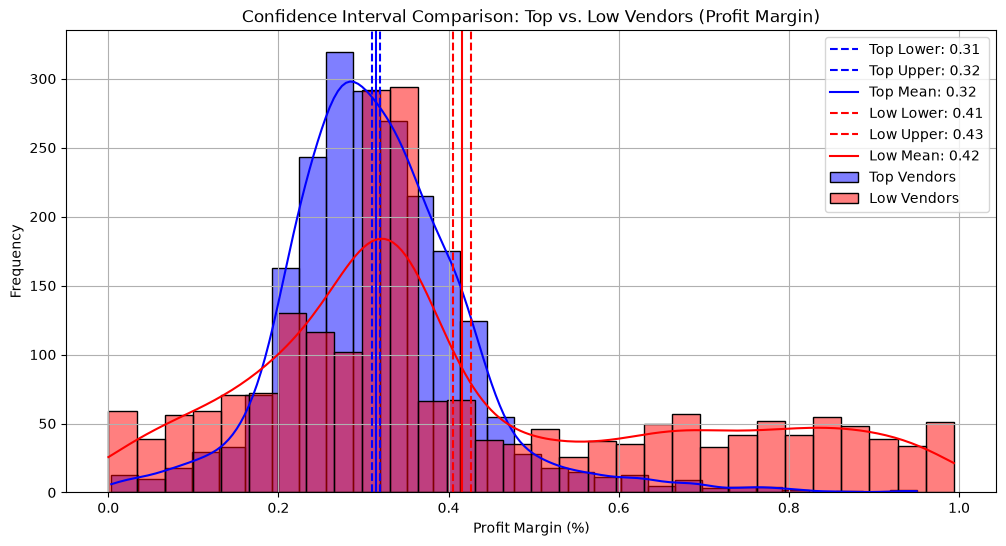

In [70]:
top_mean, top_lower, top_upper = confidence_interval(top_vendors)
low_mean, low_lower, low_upper = confidence_interval(low_vendors)

print(f"Top Vendors 95% CI: ({top_lower:.2f}, {top_upper:.2f}), Mean: {top_mean:.2f}")
print(f"Low Vendors 95% CI: ({low_lower:.2f}, {low_upper:.2f}), Mean: {low_mean:.2f}")

plt.figure(figsize=(12, 6))

# Top Vendors Plot
sns.histplot(top_vendors, kde=True, color="blue", bins=30, alpha=0.5, label="Top Vendors")
plt.axvline(top_lower, color="blue", linestyle="--", label=f"Top Lower: {top_lower:.2f}")
plt.axvline(top_upper, color="blue", linestyle="--", label=f"Top Upper: {top_upper:.2f}")
plt.axvline(top_mean, color="blue", linestyle="-", label=f"Top Mean: {top_mean:.2f}")

# Low Vendors Plot
sns.histplot(low_vendors, kde=True, color="red", bins=30, alpha=0.5, label="Low Vendors")
plt.axvline(low_lower, color="red", linestyle="--", label=f"Low Lower: {low_lower:.2f}")
plt.axvline(low_upper, color="red", linestyle="--", label=f"Low Upper: {low_upper:.2f}")
plt.axvline(low_mean, color="red", linestyle="-", label=f"Low Mean: {low_mean:.2f}")

# Finalize Plot
plt.title("Confidence Interval Comparison: Top vs. Low Vendors (Profit Margin)")
plt.xlabel("Profit Margin (%)")
plt.ylabel("Frequency")
plt.legend()
plt.grid(True)
plt.show()

In [71]:
top_threshold = df["TotalSalesDollars"].quantile(0.75)
low_threshold = df["TotalSalesDollars"].quantile(0.25)

top_vendors = df[df["TotalSalesDollars"] >= top_threshold]["ProfitMargin"].dropna()
low_vendors = df[df["TotalSalesDollars"] <= low_threshold]["ProfitMargin"].dropna()

# Perform Two-Sample T-Test
t_stat, p_value = ttest_ind(top_vendors, low_vendors, equal_var=False)

# Print results
print(f"T-Statistic: {t_stat:.4f}, P-Value: {p_value:.4f}")
if p_value < 0.05:
    print("Reject H0: There is a significant difference in profit margins between top and low-performing vendors.")
else:
    print("Fail to Reject H0: No significant difference in profit margins.")

T-Statistic: -17.0720, P-Value: 0.0000
Reject H0: There is a significant difference in profit margins between top and low-performing vendors.


In [72]:
# Save the final cleaned dataframe as a CSV file
df.to_csv("cleaned_vendor_performance.csv", index=False)
print("Data successfully exported for Power BI!")

Data successfully exported for Power BI!
